<a href="https://colab.research.google.com/github/Kishore-Krish19/ML/blob/main/Transformer_English_French_Translation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Environment Setup

In [ ]:
!pip -q install datasets tokenizers sacrebleu matplotlib

In [ ]:
import tensorflow as tf
import keras

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Keras version: 3.13.2
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Downloading the Dataset

In [ ]:
import os
import zipfile
import keras

url = "https://storage.googleapis.com/download.tensorflow.org/data/fra-eng.zip"

zip_path = keras.utils.get_file(
    fname="fra-eng.zip",
    origin=url,
    extract=False
)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/fra_eng")

print("Dataset downloaded successfully!")
print("Files:", os.listdir("/content/fra_eng"))

Dataset downloaded successfully!
Files: ['fra.txt', '_about.txt']


Reading the dataset

In [ ]:
import pathlib

text_file = pathlib.Path("/content/fra_eng/fra.txt")

with open(text_file, encoding="utf-8") as f:
    lines = f.read().splitlines()

text_pairs = []

for line in lines:
    parts = line.split("\t")
    if len(parts) >= 2:
        english = parts[0]
        french = parts[1]
        text_pairs.append((english, french))

print("Total sentence pairs:", len(text_pairs))

print("\nFirst 5 sentence pairs:\n")

for eng, fra in text_pairs[:5]:
    print("English:", eng)
    print("French :", fra)
    print("-" * 40)

Total sentence pairs: 167130

First 5 sentence pairs:

English: Go.
French : Va !
----------------------------------------
English: Hi.
French : Salut !
----------------------------------------
English: Run!
French : Cours !
----------------------------------------
English: Run!
French : Courez !
----------------------------------------
English: Who?
French : Qui ?
----------------------------------------


Visualize dataset sentence length

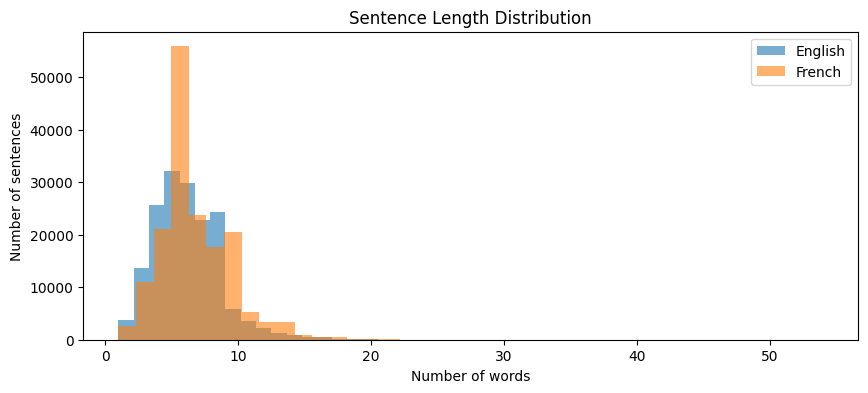

In [ ]:
import matplotlib.pyplot as plt

english_lengths = [
    len(eng.split()) for eng, fra in text_pairs
]

french_lengths = [
    len(fra.split()) for eng, fra in text_pairs
]

plt.figure(figsize=(10, 4))

plt.hist(english_lengths, bins=40, alpha=0.6, label="English")
plt.hist(french_lengths, bins=40, alpha=0.6, label="French")

plt.xlabel("Number of words")
plt.ylabel("Number of sentences")
plt.title("Sentence Length Distribution")
plt.legend()
plt.show()

3.1 Prepare and split the dataset

In [ ]:
import random

random.seed(42)

# Shuffle the complete dataset
random.shuffle(text_pairs)

# Use 30,000 sentence pairs initially
text_pairs = text_pairs[:30000]

# Add special start and end tokens to French targets
text_pairs = [
    (eng, "[start] " + fra + " [end]")
    for eng, fra in text_pairs
]

# Split: 80% train, 10% validation, 10% test
num_val = int(0.1 * len(text_pairs))
num_test = int(0.1 * len(text_pairs))

train_pairs = text_pairs[:-(num_val + num_test)]

val_pairs = text_pairs[-(num_val + num_test):-num_test]

test_pairs = text_pairs[-num_test:]

print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))
print("Testing pairs:", len(test_pairs))

print("\nExample training pair:")
print(train_pairs[0])

Training pairs: 24000
Validation pairs: 3000
Testing pairs: 3000

Example training pair:
('I blamed him for the accident.', "[start] [start] [start] [start] Je lui ai mis l'accident sur le dos. [end] [end] [end] [end]")


# Updated data split

In [ ]:

import random
import re

# Remove repeated start/end tokens
def clean_special_tokens(text):
    text = re.sub(r"(\[start\]\s*)+", "", text)
    text = re.sub(r"(\s*\[end\])+", "", text)
    return text.strip()

# Preserve original validation and test examples
val_pairs = [
    (eng, "[start] " + clean_special_tokens(fra) + " [end]")
    for eng, fra in val_pairs
]

test_pairs = [
    (eng, "[start] " + clean_special_tokens(fra) + " [end]")
    for eng, fra in test_pairs
]

# Read full dataset
with open(text_file, encoding="utf-8") as f:
    lines = f.read().splitlines()

all_pairs = []

for line in lines:
    parts = line.split("\t")

    if len(parts) >= 2:
        eng = parts[0]
        fra = clean_special_tokens(parts[1])

        all_pairs.append(
            (eng, "[start] " + fra + " [end]")
        )

# Exclude English sentences present in validation/test
held_out_english = {
    eng for eng, _ in val_pairs + test_pairs
}

train_pairs = [
    pair for pair in all_pairs
    if pair[0] not in held_out_english
]

random.seed(42)
random.shuffle(train_pairs)

# Verify dataset
print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))
print("Testing pairs:", len(test_pairs))

print("\nTraining example:", train_pairs[0])
print("Validation example:", val_pairs[0])
print("Testing example:", test_pairs[0])

train_english = {eng for eng, _ in train_pairs}

print("\nTrain/Validation overlap:",
      len(train_english & {eng for eng, _ in val_pairs}))

print("Train/Test overlap:",
      len(train_english & {eng for eng, _ in test_pairs}))


Training pairs: 155380
Validation pairs: 3000
Testing pairs: 3000

Training example: ('Come over.', '[start] Venez chez nous ! [end]')
Validation example: ('He ran too fast for me to keep up with him.', '[start] Il a couru trop vite pour que je le suive. [end]')
Testing example: ('I cannot lend this book to you.', '[start] Je ne peux pas te prêter ce livre. [end]')

Train/Validation overlap: 0
Train/Test overlap: 0


3.2 Create text vectorization layers

In [ ]:
import tensorflow as tf
import keras
import string
import re

strip_chars = string.punctuation + "¿"
strip_chars = strip_chars.replace("[", "").replace("]", "")

def custom_standardization(input_string):
    lowercase = tf.strings.lower(input_string)

    return tf.strings.regex_replace(
        lowercase,
        "[%s]" % re.escape(strip_chars),
        ""
    )

vocab_size = 15000
sequence_length = 20

source_vectorization = keras.layers.TextVectorization(
    max_tokens=vocab_size,
    output_mode="int",
    output_sequence_length=sequence_length
)

target_vectorization = keras.layers.TextVectorization(
    max_tokens=vocab_size,
    output_mode="int",
    output_sequence_length=sequence_length + 1,
    standardize=custom_standardization
)

train_english = [pair[0] for pair in train_pairs]
train_french = [pair[1] for pair in train_pairs]

source_vectorization.adapt(train_english)
target_vectorization.adapt(train_french)

print("English vocabulary size:",
      len(source_vectorization.get_vocabulary()))

print("French vocabulary size:",
      len(target_vectorization.get_vocabulary()))

English vocabulary size: 7024
French vocabulary size: 13055


3.3 Test tokenization

In [ ]:
sample_english = ["I love machine learning."]

tokenized = source_vectorization(sample_english)

print("Original sentence:", sample_english[0])
print("Tokenized sequence:", tokenized.numpy()[0])

print("\nFirst 20 English vocabulary tokens:")
print(source_vectorization.get_vocabulary()[:20])

print("\nFirst 20 French vocabulary tokens:")
print(target_vectorization.get_vocabulary()[:20])

Original sentence: I love machine learning.
Tokenized sequence: [  2 152 898 900   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0]

First 20 English vocabulary tokens:
['', '[UNK]', np.str_('i'), np.str_('you'), np.str_('to'), np.str_('the'), np.str_('a'), np.str_('is'), np.str_('tom'), np.str_('that'), np.str_('he'), np.str_('do'), np.str_('of'), np.str_('it'), np.str_('this'), np.str_('in'), np.str_('me'), np.str_('dont'), np.str_('have'), np.str_('was')]

First 20 French vocabulary tokens:
['', '[UNK]', np.str_('[start]'), np.str_('[end]'), np.str_('je'), np.str_('de'), np.str_('pas'), np.str_('que'), np.str_('à'), np.str_('la'), np.str_('ne'), np.str_('le'), np.str_('vous'), np.str_('il'), np.str_('tom'), np.str_('est'), np.str_('un'), np.str_('ce'), np.str_('a'), np.str_('tu')]


4.1 Define positional embedding

In [ ]:
from keras import layers
import keras
import tensorflow as tf

embed_dim = 128
latent_dim = 256
num_heads = 4

class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)

        self.token_embeddings = layers.Embedding(
            input_dim=vocab_size,
            output_dim=embed_dim
        )

        self.position_embeddings = layers.Embedding(
            input_dim=sequence_length,
            output_dim=embed_dim
        )

    def call(self, inputs):
        length = tf.shape(inputs)[-1]
        positions = tf.range(start=0, limit=length, delta=1)

        embedded_tokens = self.token_embeddings(inputs)
        embedded_positions = self.position_embeddings(positions)

        return embedded_tokens + embedded_positions

4.2 Build the Transformer Encoder

In [ ]:
class TransformerEncoder(layers.Layer):
    def __init__(self, embed_dim, latent_dim, num_heads, **kwargs):
        super().__init__(**kwargs)

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.dense_proj = keras.Sequential([
            layers.Dense(latent_dim, activation="relu"),
            layers.Dense(embed_dim)
        ])

        self.layernorm_1 = layers.LayerNormalization()
        self.layernorm_2 = layers.LayerNormalization()

    def call(self, inputs, padding_mask=None):
        attention_mask = None

        if padding_mask is not None:
            attention_mask = tf.expand_dims(padding_mask, axis=1)

        attention_output = self.attention(
            query=inputs,
            value=inputs,
            key=inputs,
            attention_mask=attention_mask
        )

        proj_input = self.layernorm_1(
            inputs + attention_output
        )

        proj_output = self.dense_proj(proj_input)

        return self.layernorm_2(
            proj_input + proj_output
        )

4.3 Test the encoder

In [ ]:
# Create a sample batch
sample_input = source_vectorization([
    "I love machine learning."
])

# Positional embedding layer
embedding_layer = PositionalEmbedding(
    sequence_length=sequence_length,
    vocab_size=vocab_size,
    embed_dim=embed_dim
)

# Transformer encoder
encoder_layer = TransformerEncoder(
    embed_dim=embed_dim,
    latent_dim=latent_dim,
    num_heads=num_heads
)

# Forward pass
embedded_input = embedding_layer(sample_input)

padding_mask = tf.not_equal(sample_input, 0)

encoder_output = encoder_layer(
    embedded_input,
    padding_mask=padding_mask
)

print("Input shape:", sample_input.shape)
print("Embedding shape:", embedded_input.shape)
print("Encoder output shape:", encoder_output.shape)

print("Encoder trainable parameters:",
      sum(int(tf.size(w)) for w in encoder_layer.trainable_weights))

Input shape: (1, 20)
Embedding shape: (1, 20, 128)
Encoder output shape: (1, 20, 128)
Encoder trainable parameters: 132480


4B.1 Create the Decoder class

In [ ]:
class TransformerDecoder(layers.Layer):
    def __init__(self, embed_dim, latent_dim, num_heads, **kwargs):
        super().__init__(**kwargs)

        self.self_attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.cross_attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.dense_proj = keras.Sequential([
            layers.Dense(latent_dim, activation="relu"),
            layers.Dense(embed_dim)
        ])

        self.layernorm_1 = layers.LayerNormalization()
        self.layernorm_2 = layers.LayerNormalization()
        self.layernorm_3 = layers.LayerNormalization()

    def call(
        self,
        inputs,
        encoder_outputs,
        decoder_padding_mask=None,
        encoder_padding_mask=None
    ):
        # 1. Masked self-attention
        self_attention_output = self.self_attention(
            query=inputs,
            value=inputs,
            key=inputs,
            use_causal_mask=True,
            attention_mask=(
                tf.expand_dims(decoder_padding_mask, axis=1)
                if decoder_padding_mask is not None
                else None
            )
        )

        out_1 = self.layernorm_1(
            inputs + self_attention_output
        )

        # 2. Cross-attention with encoder output
        cross_attention_output = self.cross_attention(
            query=out_1,
            value=encoder_outputs,
            key=encoder_outputs,
            attention_mask=(
                tf.expand_dims(encoder_padding_mask, axis=1)
                if encoder_padding_mask is not None
                else None
            )
        )

        out_2 = self.layernorm_2(
            out_1 + cross_attention_output
        )

        # 3. Feed-forward network
        proj_output = self.dense_proj(out_2)

        return self.layernorm_3(
            out_2 + proj_output
        )

4B.2 Test the Decoder

In [ ]:
# Sample French target
sample_french = target_vectorization([
    "[start] j'aime l'apprentissage automatique [end]"
])

# Decoder receives all tokens except the last one
decoder_input = sample_french[:, :-1]

decoder_embedding_layer = PositionalEmbedding(
    sequence_length=sequence_length,
    vocab_size=vocab_size,
    embed_dim=embed_dim
)

decoder_layer = TransformerDecoder(
    embed_dim=embed_dim,
    latent_dim=latent_dim,
    num_heads=num_heads
)

embedded_decoder_input = decoder_embedding_layer(
    decoder_input
)

decoder_padding_mask = tf.not_equal(decoder_input, 0)

decoder_output = decoder_layer(
    embedded_decoder_input,
    encoder_output,
    decoder_padding_mask=decoder_padding_mask,
    encoder_padding_mask=padding_mask
)

print("Decoder input shape:", decoder_input.shape)
print("Decoder embedding shape:", embedded_decoder_input.shape)
print("Decoder output shape:", decoder_output.shape)

print(
    "Decoder trainable parameters:",
    sum(int(tf.size(w)) for w in decoder_layer.trainable_weights)
)

Decoder input shape: (1, 20)
Decoder embedding shape: (1, 20, 128)
Decoder output shape: (1, 20, 128)
Decoder trainable parameters: 198784


4C.1 Build the complete Transformer model

In [ ]:
# English input
encoder_inputs = keras.Input(
    shape=(None,),
    dtype="int32",
    name="encoder_inputs"
)

# French decoder input
decoder_inputs = keras.Input(
    shape=(None,),
    dtype="int32",
    name="decoder_inputs"
)

# Padding masks
encoder_padding_mask = keras.ops.not_equal(encoder_inputs, 0)
decoder_padding_mask = keras.ops.not_equal(decoder_inputs, 0)

# English token + positional embeddings
encoder_embeddings = PositionalEmbedding(
    sequence_length=sequence_length,
    vocab_size=vocab_size,
    embed_dim=embed_dim
)(encoder_inputs)

# Transformer encoder
encoder_outputs = TransformerEncoder(
    embed_dim=embed_dim,
    latent_dim=latent_dim,
    num_heads=num_heads
)(
    encoder_embeddings,
    padding_mask=encoder_padding_mask
)

# French token + positional embeddings
decoder_embeddings = PositionalEmbedding(
    sequence_length=sequence_length,
    vocab_size=vocab_size,
    embed_dim=embed_dim
)(decoder_inputs)

# Transformer decoder
decoder_outputs = TransformerDecoder(
    embed_dim=embed_dim,
    latent_dim=latent_dim,
    num_heads=num_heads
)(
    decoder_embeddings,
    encoder_outputs,
    decoder_padding_mask=decoder_padding_mask,
    encoder_padding_mask=encoder_padding_mask
)

# Predict the next French token
decoder_outputs = layers.Dropout(0.2)(decoder_outputs)

final_outputs = layers.Dense(
    vocab_size,
    activation="softmax",
    name="token_predictions"
)(decoder_outputs)

# Complete model
transformer = keras.Model(
    inputs={
        "encoder_inputs": encoder_inputs,
        "decoder_inputs": decoder_inputs
    },
    outputs=final_outputs,
    name="English_French_Transformer"
)

transformer.summary()

Model: "English_French_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, None, 128) │  1,922,560 │ encoder_inputs[0… │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, None)      │          0 │ encoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, None, 128) │  1,922,560 │ decoder_inputs[0… │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, None, 128) │    132,480 │ positional_embed… │
│ (TransformerEncode… │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_3         │ (None, None)      │          0 │ decoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_decode… │ (None, None, 128) │    198,784 │ positional_embed… │
│ (TransformerDecode… │                   │            │ transformer_enco… │
│                     │                   │            │ not_equal_3[0][0… │
│                     │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_13          │ (None, None, 128) │          0 │ transformer_deco… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_predictions   │ (None, None,      │  1,935,000 │ dropout_13[0][0]  │
│ (Dense)             │ 15000)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,111,384 (23.31 MB)

 Trainable params: 6,111,384 (23.31 MB)

 Non-trainable params: 0 (0.00 B)

4C.2 Verify the model's output

In [ ]:
sample_inputs = {
    "encoder_inputs": sample_input,
    "decoder_inputs": decoder_input
}

predictions = transformer(sample_inputs, training=False)

print("English input shape:", sample_input.shape)
print("French decoder input shape:", decoder_input.shape)
print("Model output shape:", predictions.shape)
print("Total model parameters:", transformer.count_params())

English input shape: (1, 20)
French decoder input shape: (1, 20)
Model output shape: (1, 20, 15000)
Total model parameters: 6111384


5. Prepare the training data and compile the Transformer

5.2 Create the TensorFlow dataset pipeline

In [ ]:
import tensorflow as tf

batch_size = 64

def format_dataset(eng, fra):
    eng = source_vectorization(eng)
    fra = target_vectorization(fra)

    return (
        {
            "encoder_inputs": eng,
            "decoder_inputs": fra[:, :-1]
        },
        fra[:, 1:]
    )

def make_dataset(pairs, training=False):
    eng_texts, fra_texts = zip(*pairs)

    dataset = tf.data.Dataset.from_tensor_slices(
        (list(eng_texts), list(fra_texts))
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(pairs),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(batch_size)

    dataset = dataset.map(
        format_dataset,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.prefetch(tf.data.AUTOTUNE)


# STEP 1: Remove validation and test pairs from training

held_out = set(val_pairs + test_pairs)

train_pairs = [
    pair for pair in train_pairs
    if pair not in held_out
]

# STEP 2: Verify no data leakage

train_set = set(train_pairs)

print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))
print("Testing pairs:", len(test_pairs))

print("Training/Validation overlap:",
      len(train_set.intersection(val_pairs)))

print("Training/Test overlap:",
      len(train_set.intersection(test_pairs)))

# STEP 3: Recreate datasets

train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs)
test_ds = make_dataset(test_pairs)

print("\nTraining batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

# STEP 4: Verify batch shapes

for inputs, targets in train_ds.take(1):
    print("\nEncoder shape:", inputs["encoder_inputs"].shape)
    print("Decoder shape:", inputs["decoder_inputs"].shape)
    print("Target shape:", targets.shape)


Training pairs: 155380
Validation pairs: 3000
Testing pairs: 3000
Training/Validation overlap: 0
Training/Test overlap: 0

Training batches: 2428
Validation batches: 47
Testing batches: 47

Encoder shape: (64, 20)
Decoder shape: (64, 20)
Target shape: (64, 20)


5.3 Verify the batch shapes

In [ ]:
for inputs, targets in train_ds.take(1):
    print("Encoder inputs:", inputs["encoder_inputs"].shape)
    print("Decoder inputs:", inputs["decoder_inputs"].shape)
    print("Decoder targets:", targets.shape)

    print("\nExample decoder input:")
    print(inputs["decoder_inputs"][0].numpy())

    print("\nExample decoder target:")
    print(targets[0].numpy())

Encoder inputs: (64, 20)
Decoder inputs: (64, 20)
Decoder targets: (64, 20)

Example decoder input:
[   2 3559    4   64    6  220   22 1264    3    0    0    0    0    0
    0    0    0    0    0    0]

Example decoder target:
[3559    4   64    6  220   22 1264    3    0    0    0    0    0    0
    0    0    0    0    0    0]


5.4 Define the masked loss and accuracy

In [ ]:
import keras

loss_object = keras.losses.SparseCategoricalCrossentropy(
    reduction="none"
)

def masked_loss(y_true, y_pred):
    loss = loss_object(y_true, y_pred)

    mask = tf.cast(
        tf.not_equal(y_true, 0),
        dtype=loss.dtype
    )

    loss *= mask

    return tf.reduce_sum(loss) / tf.maximum(
        tf.reduce_sum(mask), 1.0
    )

def masked_accuracy(y_true, y_pred):
    predictions = tf.argmax(
        y_pred,
        axis=-1,
        output_type=y_true.dtype
    )

    matches = tf.equal(y_true, predictions)
    mask = tf.not_equal(y_true, 0)

    matches = tf.logical_and(matches, mask)

    return tf.reduce_sum(
        tf.cast(matches, tf.float32)
    ) / tf.maximum(
        tf.reduce_sum(tf.cast(mask, tf.float32)),
        1.0
    )

print("Masked loss and accuracy functions created.")

Masked loss and accuracy functions created.


5.5 Compile the Transformer

In [ ]:
transformer.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss=masked_loss,
    metrics=[masked_accuracy]
)

print("Transformer compiled successfully!")
print("Total parameters:", transformer.count_params())

Transformer compiled successfully!
Total parameters: 6111384


6. Train the Transformer Model

6.2 Training the Transformer

In [ ]:

from keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)
import keras

# Reduce the learning rate for continued training
transformer.optimizer.learning_rate.assign(0.00002) # 0.00005 -> 0.00002

print("Learning rate:", float(transformer.optimizer.learning_rate.numpy()))
print("Model parameters:", transformer.count_params())

# Early stopping - patience= 4 -> 3
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Save improved weights separately
checkpoint = ModelCheckpoint(
    filepath="final_improved_transformer.weights.h5",
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.000001,
    verbose=1
)

# Continue training the existing model
final_history = transformer.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        early_stopping,
        checkpoint,
        lr_scheduler
    ]
)


Learning rate: 1.9999999494757503e-05
Model parameters: 6111384
Epoch 1/10
2428/2428 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 1.2693 - masked_accuracy: 0.7186
Epoch 1: val_loss improved from None to 1.56192, saving model to final_improved_transformer.weights.h5

Epoch 1: finished saving model to final_improved_transformer.weights.h5
2428/2428 ━━━━━━━━━━━━━━━━━━━━ 43s 18ms/step - loss: 1.2705 - masked_accuracy: 0.7178 - val_loss: 1.5619 - val_masked_accuracy: 0.6999 - learning_rate: 2.0000e-05
Epoch 2/10
2425/2428 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 1.2471 - masked_accuracy: 0.7218
Epoch 2: val_loss improved from 1.56192 to 1.56129, saving model to final_improved_transformer.weights.h5

Epoch 2: finished saving model to final_improved_transformer.weights.h5
2428/2428 ━━━━━━━━━━━━━━━━━━━━ 82s 18ms/step - loss: 1.2507 - masked_accuracy: 0.7208 - val_loss: 1.5613 - val_masked_accuracy: 0.6997 - learning_rate: 2.0000e-05
Epoch 3/10
2426/2428 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 

7. Visualize training and validation performance

7.1 Plot loss and accuracy

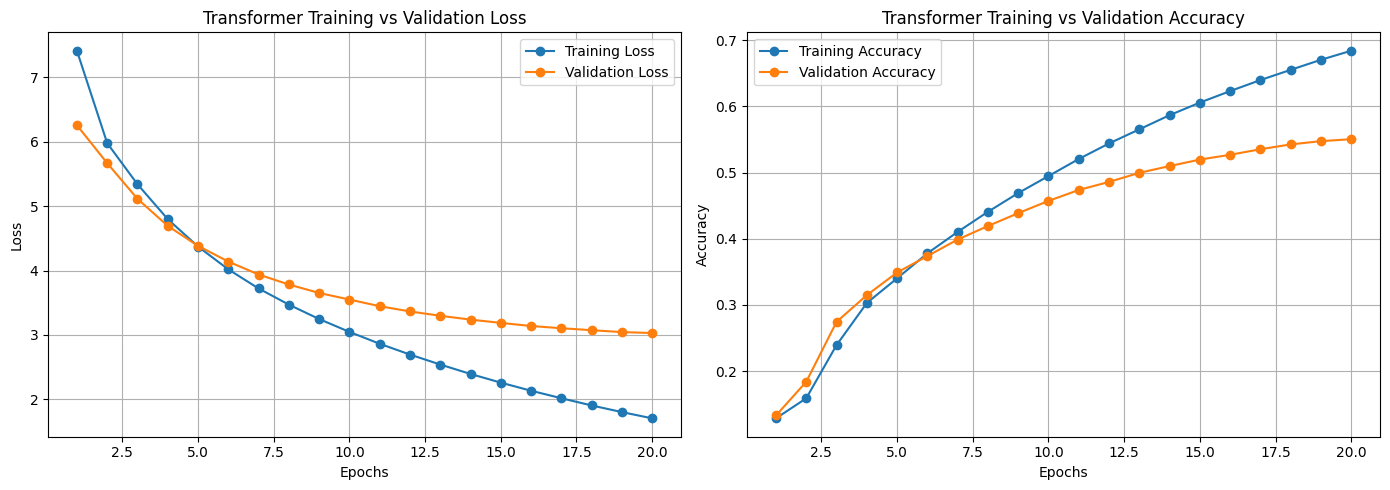

Continued training epochs: 10
Final training accuracy: 0.7072225213050842
Final validation accuracy: 0.6993774771690369
Final validation loss: 1.566409707069397


In [ ]:
import matplotlib.pyplot as plt

# Training history
train_loss = final_history.history["loss"]
val_loss = final_history.history["val_loss"]

train_acc = final_history.history["masked_accuracy"]
val_acc = final_history.history["val_masked_accuracy"]

epochs_range = range(1, len(train_loss) + 1)

plt.figure(figsize=(14, 5))

# Loss graph
plt.subplot(1, 2, 1)

plt.plot(epochs_range, train_loss, label="Training Loss", marker="o")
plt.plot(epochs_range, val_loss, label="Validation Loss", marker="o")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Transformer Training vs Validation Loss")
plt.legend()
plt.grid(True)

# Accuracy graph
plt.subplot(1, 2, 2)

plt.plot(epochs_range, train_acc, label="Training Accuracy", marker="o")
plt.plot(epochs_range, val_acc, label="Validation Accuracy", marker="o")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Transformer Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("transformer_training_results.png", dpi=300)
plt.show()


8. Generate English-to-French translations

8.2 Create the translation function

In [ ]:
import numpy as np

# French vocabulary
french_vocab = target_vectorization.get_vocabulary()

# Map token IDs back to words
index_to_word = dict(enumerate(french_vocab))

def translate_sentence(input_sentence):

    # Convert English sentence into token IDs
    tokenized_input = source_vectorization(
        [input_sentence]
    )

    # Begin French output with start token
    decoded_sentence = "[start]"

    # Generate one token at a time
    for i in range(sequence_length):

        tokenized_target = target_vectorization(
            [decoded_sentence]
        )[:, :-1]

        # Predict French vocabulary probabilities
        predictions = transformer(
            {
                "encoder_inputs": tokenized_input,
                "decoder_inputs": tokenized_target
            },
            training=False
        )

        # Select the most probable next token
        sampled_token_index = int(
            np.argmax(predictions[0, i, :])
        )

        sampled_token = index_to_word[
            sampled_token_index
        ]

        # Stop if end token is predicted
        if sampled_token == "[end]":
            break

        # Stop if padding or unknown token is predicted
        if sampled_token in ("", "[UNK]"):
            break

        # Append predicted token
        decoded_sentence += " " + sampled_token

    # Remove the start token
    return decoded_sentence.replace(
        "[start]", ""
    ).strip()

print("Translation function created successfully!")

Translation function created successfully!


8.3 Test the Transformer

In [ ]:
test_sentences = [
    "Hello.",
    "How are you?",
    "I am happy.",
    "I love you.",
    "Where are you going?",
    "Thank you.",
    "I am a student.",
    "Good morning.",
    "What is your name?",
    "I like learning."
]

print("English to French Translation\n")

for sentence in test_sentences:
    translation = translate_sentence(sentence)

    print("English:", sentence)
    print("French :", translation)
    print("-" * 45)

English to French Translation

English: Hello.
French : salut
---------------------------------------------
English: How are you?
French : comment estu
---------------------------------------------
English: I am happy.
French : je suis heureux
---------------------------------------------
English: I love you.
French : je vous aime
---------------------------------------------
English: Where are you going?
French : où allezvous
---------------------------------------------
English: Thank you.
French : merci
---------------------------------------------
English: I am a student.
French : je suis étudiant
---------------------------------------------
English: Good morning.
French : bon matin
---------------------------------------------
English: What is your name?
French : quel est ton nom
---------------------------------------------
English: I like learning.
French : jaime apprendre
---------------------------------------------


9. Evaluate the Transformer using BLEU score

9.1 Install SacreBLEU

In [ ]:
!pip -q install sacrebleu

9.2 Calculate BLEU on a test sample

In [ ]:
import random
import sacrebleu
import re

random.seed(42)

sample_test_pairs = random.sample(test_pairs, 100)

references = []
predictions = []

def clean_translation(text):
    text = text.replace("[start]", "").replace("[end]", "")
    text = text.strip().lower()
    text = re.sub(r"\s+", " ", text)
    return text

for i, (english, french) in enumerate(sample_test_pairs):

    predicted_french = translate_sentence(english)

    references.append(clean_translation(french))
    predictions.append(clean_translation(predicted_french))

    if (i + 1) % 20 == 0:
        print(f"Translated {i + 1}/100 sentences")

# Corpus BLEU score
bleu = sacrebleu.corpus_bleu(
    predictions,
    [references],
    tokenize="13a"
)

print("\nBLEU Score:", round(bleu.score, 2))

print("\nSample translations:\n")

for i in range(5):
    print("English  :", sample_test_pairs[i][0])
    print("Reference:", references[i])
    print("Predicted:", predictions[i])
    print("-" * 45)

Translated 20/100 sentences
Translated 40/100 sentences
Translated 60/100 sentences
Translated 80/100 sentences
Translated 100/100 sentences

BLEU Score: 27.31

Sample translations:

English  : Lake Towada is famous for its beauty.
Reference: le lac towada est connu pour sa beauté.
Predicted: le lac
---------------------------------------------
English  : Please smile.
Reference: souriez, s'il vous plaît !
Predicted: veuillez vous prie veuillez faire
---------------------------------------------
English  : He asked about you.
Reference: il s'est enquis de vous.
Predicted: il vous a demandé de toi
---------------------------------------------
English  : I thought that she was pregnant.
Reference: je croyais que elle était enceinte.
Predicted: je pensais quelle était enceinte
---------------------------------------------
English  : They went crazy.
Reference: ils sont devenus fous.
Predicted: ils sont devenus fous
---------------------------------------------


10. Evaluate the complete test dataset

In [ ]:

import sacrebleu
import tensorflow as tf
import string
import re

# Normalize both references and predictions consistently
def normalize_for_bleu(text):
    text = text.replace("[start]", "").replace("[end]", "")
    text = text.lower()

    # Match our training-time punctuation removal
    strip_chars = string.punctuation + "¿"
    strip_chars = strip_chars.replace("[", "").replace("]", "")

    text = re.sub(f"[{re.escape(strip_chars)}]", "", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip()

full_references = []
full_predictions = []

for i, (english, french) in enumerate(test_pairs):
    predicted = translate_sentence(english)

    full_predictions.append(normalize_for_bleu(predicted))
    full_references.append(normalize_for_bleu(french))

    if (i + 1) % 500 == 0:
        print(f"Evaluated {i + 1}/{len(test_pairs)} sentences")

final_bleu = sacrebleu.corpus_bleu(
    full_predictions,
    [full_references],
    tokenize="13a"
)

print("\nFinal Test BLEU:", round(final_bleu.score, 2))
print("Total evaluated sentences:", len(full_predictions))


Evaluated 500/3000 sentences
Evaluated 1000/3000 sentences
